# Handwritten Math-to-LaTeX Recognition System

## 1. Setup

Before we begin building the model, we need to set up the right environment.

A neural network starts out as a pile of random numbers, and randomness shows up again and again when the data gets shuffled and when training images get randomly distorted. Setting `SEED = 42` pins all of those random streams to the same starting point so that re-running the notebook produces the same result. Without it you can never tell whether a change you made actually helped or whether you just got lucky.

A neural network is really just a very long chain of matrix multiplications. A CPU works through these a few at a time, while a GPU does thousands in parallel, which is the difference between training finishing in half an hour and taking all day. The cell picks a GPU if one is available and falls back to CPU if not. I highly recommend using a device with a GPU if you choose to run the model yourself.

The two data directories exist because Google's MathWriting dataset doesn't ship pictures. It ships pen trajectories, meaning the actual sequence of (x, y) coordinates the pen moved through while someone wrote each expression. `MW_DIR` holds that raw form and `MW_IMG_DIR` holds the images rendered from it. Keeping them separate matters because rendering is slow, done once, and reused on every later run.

`IMG_H, IMG_W = 96, 480` sets the canvas every expression eventually gets fitted into. Convolutional neural networks (CNN), neural networks built for grid-like data such as images, require all inputs to be the same size, and these dimensions are short and wide because MathWriting expressions are all single-line. These two numbers determine how long a sequence the model reads, and they're the reason stacked multi-line equations are out of scope.

In [ ]:
# download the necessary dependencies
!pip install torch torchvision pandas pillow matplotlib tqdm

In [ ]:
# import the necessary dependencies
import os, math, random, time, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# set a seed for reproducibility
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# use a GPU whenever available
if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

import sys
print("Using device:", device)
if device.type == "cpu":
    print("python     :", sys.executable)         # must contain \venv\Scripts\ on Windows
    print("torch      :", torch.__version__)      
    print("cuda build :", torch.version.cuda)
    print("\nWARNING: running on CPU. Training will take many hours. "
          "See the environment notes above, and remember to RESTART THE KERNEL "
          "after reinstalling torch.")

# load Google's MathWriting dataset
DATA_DIR   = Path("data")
MW_DIR     = DATA_DIR / "mathwriting-2024"        
MW_IMG_DIR = DATA_DIR / "mathwriting_images"      
IMG_H, IMG_W = 96, 480                            

print("\nMW_DIR exists:", MW_DIR.exists())
if MW_DIR.exists():
    print("contents:", [p.name for p in MW_DIR.iterdir()])

python     : c:\Users\muhdn\OneDrive\Desktop\projects\ocr\venv\Scripts\python.exe
torch      : 2.11.0+cu128
cuda build : 12.8
Using device: cuda

MW_DIR exists: True
contents: ['symbols', 'symbols.jsonl', 'synthetic', 'synthetic-bboxes.jsonl', 'train', 'valid']


## 2. Loading the Dataset

Before a model can learn anything, we need to give it examples to learn from. Supervised learning needs matched pairs of inputs and correct answers — the model only learns by being shown an example, making a guess, and being corrected.

Each file in the dataset is XML describing one handwritten expression as a set of traces. A trace is a single continuous pen movement from pen-down to pen-up, so a handwritten "x" is two traces, a "+" is two, and a "2" is one. `read_inkml()` extracts the LaTeX answer and the list of traces. The `INKML_NS` map is required because the XML is namespaced, and without it the parser matches nothing at all and returns empty results with no error to tell you why.

Since the model being built here reads pixels, those strokes have to become images. `render_ink()` finds the boundaries of the ink, scales it to fit the canvas without distorting the proportions, and draws each stroke as a connected line. Scaling to the ink's actual extent rather than the raw coordinate range matters because that coordinate space is arbitrary and mostly empty.

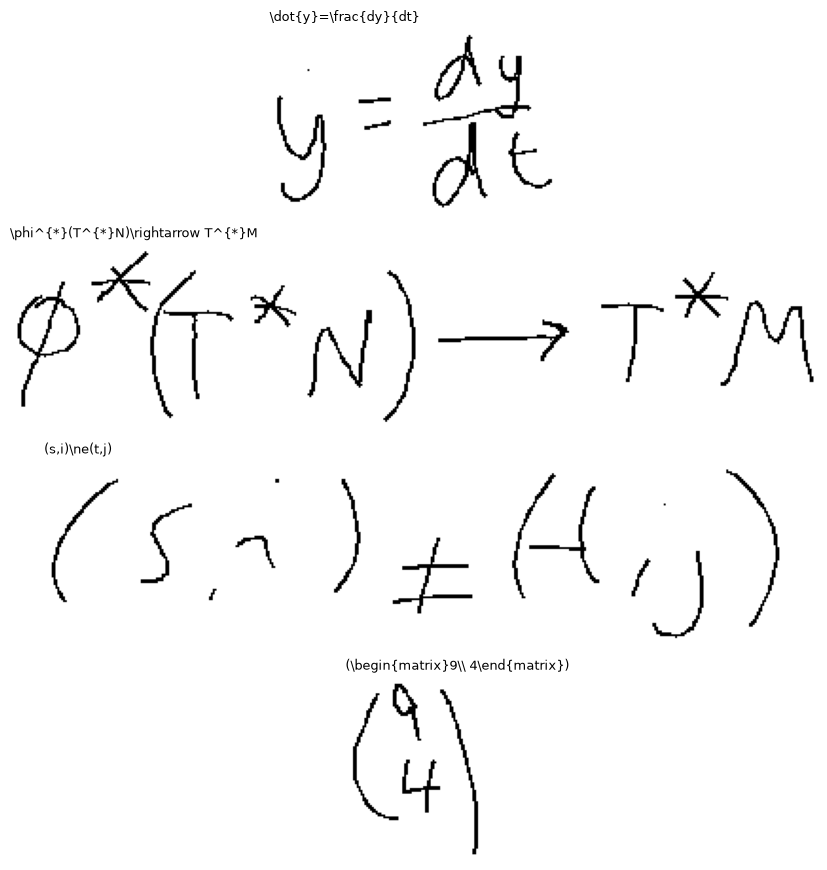

In [ ]:
import xml.etree.ElementTree as ET

INKML_NS = {"i": "http://www.w3.org/2003/InkML"}

# extracts the LaTeX equation and its strokes
def read_inkml(path):
    root = ET.parse(path).getroot()
    label = None
    for ann in root.findall("i:annotation", INKML_NS):
        if ann.get("type") == "normalizedLabel":
            label = ann.text
    if label is None:
        for ann in root.findall("i:annotation", INKML_NS):
            if ann.get("type") == "label":
                label = ann.text
    strokes = []
    for trace in root.findall("i:trace", INKML_NS):
        pts = []
        for triplet in trace.text.strip().split(","):
            vals = triplet.split()
            pts.append((float(vals[0]), float(vals[1])))
        if pts:
            strokes.append(pts)
    return label, strokes

# transfer the strokes to a canvas with black ink
def render_ink(strokes, height=IMG_H, max_width=IMG_W, margin=4, line_width=2):
    xs = [x for s in strokes for x, _ in s]
    ys = [y for s in strokes for _, y in s]
    x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
    w, h = max(x1 - x0, 1e-6), max(y1 - y0, 1e-6)
    scale = min((height - 2 * margin) / h, (max_width - 2 * margin) / w)
    W = int(w * scale) + 2 * margin
    img = Image.new("L", (max(W, 8), height), 255)
    draw = ImageDraw.Draw(img)
    for s in strokes:
        pts = [(margin + (x - x0) * scale,
                margin + (y - y0) * scale + (height - 2 * margin - h * scale) / 2)
               for x, y in s]
        if len(pts) == 1:
            draw.ellipse([pts[0][0]-1, pts[0][1]-1, pts[0][0]+1, pts[0][1]+1], fill=0)
        else:
            draw.line(pts, fill=0, width=line_width, joint="curve")
    return img

# verify the conversion worked correctly and the right equation is paired
some_files = sorted((MW_DIR / "train").glob("*.inkml"))[:4]
fig, axes = plt.subplots(len(some_files), 1, figsize=(12, 2.2 * len(some_files)))
for ax, f in zip(np.atleast_1d(axes), some_files):
    lab, strokes = read_inkml(f)
    ax.imshow(render_ink(strokes), cmap="gray"); ax.axis("off")
    ax.set_title(lab[:70], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

Not every sample survives this stage. `render_split()` skips files that fail to parse, have no label, or have no strokes, and `MAX_LABEL_CHARS = 220` drops anything whose LaTeX label is longer than 220 characters. Setting a maximum label length is more about cost than correctness. A handful of expressions in MathWriting are page-long formulas, and because `MAX_LEN` is derived from the longest label we keep, a single outlier would raise the decoding budget for every prediction the model ever makes. Dropping them keeps generation bounded and training efficient, at the cost of a few hundred samples the model would have struggled with anyway.

The three-way split is the most important idea here:

- **Training set** (~230,000 images): this is what the model learns from. Its weights get adjusted to fit these examples
- **Validation set** (2,500 images): this is never learned from, but gets checked after every pass through the training data. It's how you decide when the model is at its best, and how you catch overfitting (when a model starts memorizing its training examples instead of learning general rules). An overfitted model scores beautifully on data it has seen and poorly on anything new
- **Test set** (500 images): this is touched exactly once, at the very end. It stands in for handwriting the model has never encountered, which makes it the only number that estimates real-world accuracy. If we looked at the test set repeatedly and tuned the model against it, we'd quietly turn it into a second validation set and the number would stop meaning anything

Typically, a dataset would be split into a training/validation/test split of 80/10/10 as a default. That convention is aimed at small datasets, where holding back a large fraction is the only way to get a held-out set big enough to measure anything. With ~230,000 samples, what matters is the absolute size of the validation and test sets, not their percentage. A few thousand validation images are plenty to track overfitting, and every image not held back is one more the model can learn from, so almost everything goes to training.

Finally, rendering ~230,000 files takes a long time, so the resulting paths and labels get cached in a CSV and later runs skip rendering entirely. Changing `IMG_H`/`IMG_W` or the number of training images means deleting the cache and the rendered PNGs, or the notebook will reuse stale ones.

Note: the public archive ships `train/` and `valid/` but no `test/` folder, so the test set is carved out of the validation data. The two end up as disjoint sets of images, and both come from writers who don't appear in training, so the estimate still holds up.

In [ ]:
# set the number of training, validation, and testing images
# MAX_LABEL_CHARS drops handwritings with LaTeX labels over the specified amount
N_TRAIN = 229_864       
N_VAL   = 3_000         
N_TEST  = 500           
MAX_LABEL_CHARS = 220   

# render handwritings to PNGs
def render_split(split, n, out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    files = sorted((MW_DIR / split).glob("*.inkml"))
    if not files:
        raise FileNotFoundError(
            f"No .inkml files in {MW_DIR / split}. Contents of {MW_DIR}: "
            f"{[p.name for p in MW_DIR.iterdir()] if MW_DIR.exists() else 'MISSING'}")
    random.Random(SEED).shuffle(files)
    rows = []
    pbar = tqdm(files, desc=f"rendering {split}", total=len(files))
    for f in pbar:
        if len(rows) >= n:
            break
        try:
            label, strokes = read_inkml(f)
        except ET.ParseError:
            continue
        if not label or not strokes or len(label) > MAX_LABEL_CHARS:
            continue
        png = out_dir / (f.stem + ".png")
        if not png.exists():                      
            render_ink(strokes).save(png)
        rows.append({"image": str(png), "id": f.stem, "latex": label})
        pbar.set_postfix(kept=len(rows))
    return pd.DataFrame(rows)

# load the training and validation data into a CSV
cache = DATA_DIR / "mathwriting_rendered_mwonly.csv"
if cache.exists():
    df_all = pd.read_csv(cache)
    train_df = df_all[df_all["split"] == "train"].reset_index(drop=True)
    val_df   = df_all[df_all["split"] == "valid"].reset_index(drop=True)
    test_df  = df_all[df_all["split"] == "test"].reset_index(drop=True)
else:
    train_df = render_split("train", N_TRAIN, MW_IMG_DIR / "train")
    valid_all = render_split("valid", N_VAL, MW_IMG_DIR / "valid")
    test_df = valid_all.iloc[:N_TEST].reset_index(drop=True)
    val_df  = valid_all.iloc[N_TEST:].reset_index(drop=True)
    for d, s in [(train_df, "train"), (val_df, "valid"), (test_df, "test")]:
        d["split"] = s
    pd.concat([train_df, val_df, test_df]).to_csv(cache, index=False)

print(f"{len(train_df)} train / {len(val_df)} val / {len(test_df)} test images")
assert len(train_df) and len(val_df) and len(test_df), "a split is empty — check MW_DIR"

rendering valid:  19%|█▉        | 3000/15674 [00:27<01:56, 108.85it/s, kept=3000]


226364 train / 2500 val / 500 test images


## 3. Tokenizing the LaTeX and Building the Vocabulary

A neural network can't output text, only numbers. This section builds the dictionary that translates between the two in both directions.

The first decision is what counts as a unit. The target output is LaTeX source like `\frac{1}{2}` or `x^{2}`, and treating those as individual characters would be both wasteful and fragile, since `\frac` would become five separate decisions and any one of them going wrong produces a command that doesn't exist. `tokenize()` splits on meaningful units instead: a whole command like `\frac` is one token, and so is a single character like `x` or `{`. The regex ordering is deliberate here, because the command pattern has to be tried before the escaped-character pattern or `\frac` gets chopped into `\f` plus leftovers.

Every distinct token in the dataset then gets an integer ID. `itos` maps IDs to tokens, `stoi` goes the other way around, and `VOCAB_SIZE` determines how wide the model's final output layer needs to be, since at every step the model produces one score per vocabulary entry.

Four of those IDs don't correspond to real LaTeX. They're control signals, and each solves a different problem:

- `<sos>`: the starting input that kicks off generation
- `<eos>`: how the model tells us it's finished. It predicts this token when the expression is complete, which is what lets generation stop on its own instead of running forever
- `<pad>`: filler, because sequences in a batch have to be the same length. These positions are excluded from both the loss and the accuracy
- `<unk>`: catches anything not in the vocabulary

They take IDs 0 through 3, which the hardcoded `PAD_ID` through `UNK_ID` constants depend on.

`encode()` turns a LaTeX string into the integer sequence the model trains against, wrapped in `<sos>` and `<eos>`. `decode()` runs the other direction on predictions: it stops at `<eos>`, drops the control tokens, and reinserts a space after each `\command` so that `\frac` followed by `x` doesn't fuse into the meaningless `\fracx`.

`MAX_LEN` is the longest label in the dataset plus a little slack, capped at 320. Further down the line, the model generates one token at a time with no built-in limit, so this is the hard stop that prevents an infinite loop when `<eos>` never arrives.

In [ ]:
import re

TOKEN_RE = re.compile(r"\\[a-zA-Z]+|\\.|\s+|\S")

# split LaTeXs string into token strings
def tokenize(latex: str):
    return [" " if t.isspace() else t for t in TOKEN_RE.findall(latex)]

PAD, SOS, EOS, UNK = "<pad>", "<sos>", "<eos>", "<unk>"
all_label_strings = pd.concat([train_df["latex"], val_df["latex"], test_df["latex"]])
all_tokens = sorted({t for s in all_label_strings for t in tokenize(str(s))})
itos = [PAD, SOS, EOS, UNK] + all_tokens
stoi = {t: i for i, t in enumerate(itos)}
PAD_ID, SOS_ID, EOS_ID, UNK_ID = 0, 1, 2, 3
VOCAB_SIZE = len(itos)
print(f"Vocabulary size: {VOCAB_SIZE}")

# convert LaTeX strings into integer token IDS
def encode(latex):
    return [SOS_ID] + [stoi.get(t, UNK_ID) for t in tokenize(latex)] + [EOS_ID]

# convert integer token IDs into LaTeX strings
def decode(ids):
    out = []
    for i in ids:
        if i == EOS_ID: break
        if i in (PAD_ID, SOS_ID): continue
        out.append(itos[i])
    s = ""
    for t in out:
        s += t + " " if (t.startswith("\\") and len(t) > 1 and t[1].isalpha()) else t
    return re.sub(r"\s+", " ", s).strip()

MAX_LEN = min(max(len(encode(str(s))) for s in all_label_strings) + 10, 320)
print("Decoding budget MAX_LEN =", MAX_LEN)

Vocabulary size: 232
Decoding budget MAX_LEN = 151


## 4. Preprocessing, Augmenting, and Batching

Three jobs here: get every image into one identical format, randomly generate extra variety so the model generalizes, and group samples to maximize GPU usage.

A model learns from whatever you feed it and can't tell noise from signal, which means any inconsistency in the input gets learned as though it meant something. `preprocess()` removes that inconsistency by turning images to grayscale, since ink color carries no information and one channel instead of three cuts the work by two-thirds. A channel is one full grid of numbers covering the image: a color photo needs three (more popular known as RGB values), while a grayscale image needs only one for brightness. Polarity gets normalized by checking average brightness and inverting when needed, so ink always ends up as high values on a dark background. That step exists because the dataset's PNGs are black-on-white while the web app's drawing canvas may send the opposite, and to the model those are entirely different images. Everything then gets scaled to fit 96x480 with proportions preserved and pasted onto a blank canvas rather than stretched, because stretching distorts character shapes and shape is the whole signal. Last, pixel values get normalized from 0-255 down to the range -1 to 1, since large, badly-scaled numbers destabilize training and centering around zero makes the optimization better behaved.

The output is a tensor, which is just a multi-dimensional array of numbers and the only thing PyTorch operates on. Here its shape is `(1, 96, 480)`: one channel, 96 rows, 480 columns.

`train_aug` applies small random rotations, shifts, rescalings, shears, and pixel noise to each training image, differently every single time that image is seen. This is data augmentation, and the reasoning is that real handwriting is never twice identical. A model trained on unvarying images learns that exact rendering and then fails on anything slightly rotated or differently sized. Augmentation effectively expands the dataset and forces the model to learn what a "2" is rather than where its pixels happened to sit. It's applied only to training data, because validation and test have to stay clean or the scores end up measuring performance on distortions nobody will ever submit.

`MathDataset` is an index: ask for item *i* and it loads that image, preprocesses it, augments it if this is training data, and encodes the label. The `DataLoader()` wraps it to serve batches of 32. Batching exists because a GPU computing 32 images at once is nearly as fast as computing one, making it close to free throughput, and it also stabilizes learning since each weight update is averaged over 32 examples instead of swinging around on individual ones.

`collate()` assembles those batches. Images stack directly because they're all the same size, but labels don't, since expressions vary in length. Each batch is padded out to its own longest label rather than to a global maximum, which keeps wasted computation down. `shuffle=True` on the training loader reorders data every pass so the model can't learn anything from example ordering. Validation and test stay unshuffled, since their order is irrelevant and reproducibility is more useful.

In [ ]:
import torchvision.transforms as T

# turns an image to grayscale and scale it to size
def preprocess(img: Image.Image) -> torch.Tensor:
    img = img.convert("L")
    a = np.array(img, dtype=np.float32) / 255.0
    if a.mean() > 0.5:
        a = 1.0 - a
    img = Image.fromarray((a * 255).astype(np.uint8))
    w, h = img.size
    scale = min(IMG_H / h, IMG_W / w)
    nw, nh = max(1, int(w * scale)), max(1, int(h * scale))
    img = img.resize((nw, nh), Image.BILINEAR)
    canvas = Image.new("L", (IMG_W, IMG_H), 0)
    canvas.paste(img, (0, (IMG_H - nh) // 2))
    x = torch.from_numpy(np.array(canvas, dtype=np.float32) / 255.0)
    return ((x - 0.5) / 0.5).unsqueeze(0)

# random handwriting noise to add variation to the training
train_aug = T.Compose([
    T.RandomAffine(degrees=2.5, translate=(0.02, 0.04), scale=(0.9, 1.05),
                   shear=4, fill=-1.0),
    T.Lambda(lambda x: torch.clamp(x + 0.03 * torch.randn_like(x), -1, 1)),
])

# serves one image and label pair at a time
class MathDataset(Dataset):
    def __init__(self, df, augment=False):
        self.df, self.augment = df, augment
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        x = preprocess(Image.open(row["image"]))
        if self.augment:
            x = train_aug(x)
        y = torch.tensor(encode(str(row["latex"])), dtype=torch.long)
        return x, y

# create a batch of images
def collate(batch):
    xs, ys = zip(*batch)
    x = torch.stack(xs)
    L = max(len(y) for y in ys)
    y = torch.full((len(ys), L), PAD_ID, dtype=torch.long)
    for i, seq in enumerate(ys):
        y[i, :len(seq)] = seq
    return x, y

BATCH = 32
NUM_WORKERS = 0

# loading the batches of data into training, validation, and testing
train_loader = DataLoader(MathDataset(train_df, augment=True), batch_size=BATCH,
                          shuffle=True,  collate_fn=collate, num_workers=NUM_WORKERS)
val_loader   = DataLoader(MathDataset(val_df), batch_size=BATCH,
                          shuffle=False, collate_fn=collate, num_workers=NUM_WORKERS)
test_loader  = DataLoader(MathDataset(test_df), batch_size=BATCH,
                          shuffle=False, collate_fn=collate, num_workers=NUM_WORKERS)
xb, yb = next(iter(train_loader))
print("image batch:", xb.shape, "| label batch:", yb.shape)

image batch: torch.Size([32, 1, 96, 480]) | label batch: torch.Size([32, 48])


## 5. Building the Model (CNN Encoder + Transformer Decoder)

Now we build the model itself. The task is image in, text out, so we will use the standard design of one network to understand the picture, another to write the answer.

An encoder reads the input and compresses it into a set of vectors that represent what's in it, without producing any output of its own. A decoder takes that representation and generates the answer one piece at a time. Splitting the work this way is the usual approach whenever the input and output are different kinds of things or different lengths - translation, speech-to-text, captioning, and transcription all use it. Here the encoder is a CNN because the input is an image, and the decoder is a Transformer because the output is a sequence.

A Transformer is an architecture built around attention, which means that instead of walking through a sequence step by step and carrying a summary forward, every position can look directly at every other position and decide what's relevant. That matters for LaTeX, where a closing brace may depend on something twenty tokens earlier, and where the symbol being written depends on one specific patch of the image.

A CNN works by sliding small learnable filters (here 3x3) across the image. Each filter responds to one kind of local pattern, like an edge at a particular angle or a curve or a junction. Early layers pick up simple strokes, and because later layers look at the outputs of earlier ones, they combine those into larger structures: loops, digit shapes, fraction bars. This is why CNNs beat treating an image as a flat list of pixels. They exploit the facts that nearby pixels are related and that a "2" is a "2" wherever it shows up.

Each block has three supporting pieces. BatchNorm rescales the intermediate values to keep them in a sane range, which speeds up and stabilizes training. ReLU, which is just `max(0, x)`, adds non-linearity, and without something like it the stacked layers would collapse mathematically into a single layer that could only learn straight-line relationships. MaxPool2d halves the width and height by keeping the strongest response in each 2x2 region, throwing away precise pixel positions that don't matter while keeping what was found, and shrinking the computation along the way.

Three of the four blocks pool, so a 96x480 input becomes a 12x60 grid of 256-number feature vectors. Flattened, that's 720 visual tokens, which is the sequence the decoder reads. The fourth block adds depth without pooling.

Flattening that grid throws away where in the image each vector came from, and for math that's fatal: `x^2` and `x_2` contain identical ink and differ only in whether the 2 sits above or below. `_build_pos2d()` fixes it by adding a distinctive sinusoidal pattern to each position, with half the 256 dimensions encoding row and half encoding column, so the decoder can tell vertical position apart.

The decoder generates LaTeX one token at a time, and its core mechanism is attention. For each token it's about to produce, it computes how relevant every available piece of information is and weights its reading accordingly. Two kinds operate here:

* Self-attention: looks back at tokens already generated, so after emitting `\frac{1}` the model knows it's inside a numerator.
* Cross-attention: looks at the 720 visual tokens from the encoder, letting the model focus on the specific region of the image holding the symbol it's currently transcribing.

That combination is what makes this architecture work because it can learn to read left-to-right and to glance up at a superscript at the right moment without anyone programming either behavior.

`nn.Embedding()` converts each token ID into a learned 256-number vector, which lets the model discover on its own that `\alpha` and `\beta` behave similarly, and `padding_idx` keeps padding contributing nothing. `PositionalEncoding1D` handles the same position problem as above but for the decoder's own token order. `nhead=8` runs attention eight times in parallel with different learned focuses and combines the results, `num_layers=4` stacks four decoder layers each refining the last, and `norm_first=True` is a stability choice that makes deeper Transformers train more reliably.

In `forward()`, the causal mask hides all future positions so the prediction at step *i* can only use tokens before *i*. During training the model is shown the correct answer as input, so without this mask it would just read ahead to the token it's supposed to predict, score a perfect loss, and learn nothing usable. It's the highest-consequence line in the cell. The pad mask tells attention to ignore `<pad>` filler, which carries no information.

The head is a final linear layer mapping each 256-dimensional output to one score per vocabulary token. Those raw scores are called logits, and the largest one is the model's preferred next token. The printed parameter count is how many individual values get adjusted during training.

In [ ]:
D_MODEL = 256

# turns the input image into a sequence the Transformer can attend over
class CNNEncoder(nn.Module):
    def __init__(self, d_model=D_MODEL):
        super().__init__()
        def block(cin, cout, pool):
            layers = [nn.Conv2d(cin, cout, 3, padding=1),
                      nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
            if pool: layers.append(nn.MaxPool2d(2))
            return layers
        self.cnn = nn.Sequential(
            *block(1,    64, True),
            *block(64,  128, True),
            *block(128, 256, True),
            *block(256, d_model, False),
        )
        self.pos2d = None

    # 2D sinusoidal positional encoding
    def _build_pos2d(self, h, w, d, device):
        def sincos(n, d):
            pos = torch.arange(n, dtype=torch.float32).unsqueeze(1)
            div = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-math.log(10000.0) / d))
            pe = torch.zeros(n, d)
            pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
            return pe
        row = sincos(h, d // 2).unsqueeze(1).expand(h, w, d // 2)
        col = sincos(w, d // 2).unsqueeze(0).expand(h, w, d // 2)
        return torch.cat([row, col], dim=-1).reshape(h * w, d).to(device)

    def forward(self, x):
        f = self.cnn(x)
        B, C, H, W = f.shape
        f = f.flatten(2).transpose(1, 2)
        if self.pos2d is None or self.pos2d.shape[0] != H * W:
            self.pos2d = self._build_pos2d(H, W, C, f.device)
        return f + self.pos2d

# 1D sinusoidal positional encoding
class PositionalEncoding1D(nn.Module):
    def __init__(self, d_model=D_MODEL, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div); pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[: x.size(1)]

# the full model
class Math2LaTeX(nn.Module):
    def __init__(self, vocab_size, d_model=D_MODEL, nhead=8, num_layers=4, ff=1024, dropout=0.1):
        super().__init__()
        self.encoder = CNNEncoder(d_model)
        self.embed   = nn.Embedding(vocab_size, d_model, padding_idx=PAD_ID)
        self.pos1d   = PositionalEncoding1D(d_model)
        layer = nn.TransformerDecoderLayer(d_model, nhead, ff, dropout,
                                           batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, num_layers)
        self.head    = nn.Linear(d_model, vocab_size)

    def forward(self, images, tgt):
        memory = self.encoder(images)
        t = self.pos1d(self.embed(tgt))
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), diagonal=1)
        pad_mask = tgt.eq(PAD_ID)
        h = self.decoder(t, memory, tgt_mask=causal, tgt_key_padding_mask=pad_mask)
        return self.head(h)

model = Math2LaTeX(VOCAB_SIZE).to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters())/1e6:.2f}M")

Parameters: 5.29M


## 6. Training

This is where learning happens, and the underlying idea is simple: show the model an example, measure how wrong it is, nudge every parameter slightly in the direction that would have made it less wrong, and repeat a few hundred thousand times.

Inside `run_epoch()`, each batch goes through the same sequence. First the labels get shifted, so the model is fed the correct sequence up to position *i* and asked to predict *i+1*. This is teacher forcing: during training the model always sees true previous tokens rather than its own possibly-wrong guesses, which makes learning much faster and more stable. It also creates a mismatch with inference, where the model has no choice but to consume its own output.

Then the forward pass produces logits, and cross-entropy loss compares the predicted probability distribution against the true next token. The result is one number, low when the model confidently assigns high probability to the right token and high when it doesn't. `ignore_index=PAD_ID` keeps padding out of the calculation so the model isn't rewarded for predicting filler, and `label_smoothing=0.1` softens the target, asking for roughly 90% confidence instead of 100%, which discourages overconfidence and usually improves generalization.

`loss.backward()` runs backpropagation, working backward through the network to compute how much each of the millions of parameters contributed to the error. Those are the gradients, meaning the direction and size of the change that would reduce the loss. Before applying them, `clip_grad_norm_` caps the overall magnitude, because occasionally a batch produces an enormous gradient that would knock the weights into nonsense and clipping bounds the damage.

`optimizer.step()` applies the update. The optimizer is AdamW, which adapts the step size per parameter based on recent gradient history and applies weight decay, a mild pull of all weights toward zero that discourages the model from leaning on any single extreme value. The learning rate controls how big each step is, and getting it wrong in either direction is costly: too large and training diverges, too small and training gets too slow. The schedule handles this in two phases. For the first epoch it warms up, ramping from near-zero to full rate, because large steps on a freshly randomized model are destructive. After that it decays along a cosine curve toward zero, taking big strides early while the model is bad and progressively finer ones as it converges.

Validation runs the identical loop with `optimizer=None`, which skips the backward pass and every update. It measures without learning.

An epoch is one complete pass over the training data, and `EPOCHS = 15` means fifteen of them. Both training and validation loss get recorded each time, and comparing the two curves is the main diagnostic you have. Both falling means the model is learning. Training loss falling while validation loss rises means overfitting, and the model has started memorizing rather than generalizing. Neither falling means something is wrong with the learning rate, the architecture, or the data.

Weights only get saved when validation loss hits a new low, so `best.pt` holds the best-generalizing version rather than whatever the last epoch happened to produce. If the model overfits in later epochs, that damage never makes it to disk. This is also precisely why validation and test have to be different data, since picking a checkpoint based on validation performance is itself a form of fitting to it.

The `RETRAIN` flag exists because training takes hours. It means a kernel restart or an accidental re-run won't wipe that work and start over.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, desc=""):
    train = optimizer is not None
    model.train(train)
    total_loss, total_correct, total_tokens = 0.0, 0, 0
    pbar = tqdm(loader, desc=desc, leave=False)
    with torch.set_grad_enabled(train):
        for x, y in pbar:
            x, y = x.to(device), y.to(device)
            inp, tgt = y[:, :-1], y[:, 1:]
            logits = model(x, inp)
            loss = criterion(logits.reshape(-1, VOCAB_SIZE), tgt.reshape(-1))
            if train:
                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if scheduler: scheduler.step()
            mask = tgt.ne(PAD_ID)
            total_loss    += loss.item() * mask.sum().item()
            total_correct += (logits.argmax(-1).eq(tgt) & mask).sum().item()
            total_tokens  += mask.sum().item()
            pbar.set_postfix(loss=f"{total_loss/total_tokens:.3f}",
                             acc=f"{total_correct/total_tokens:.3f}")
    return total_loss / total_tokens, total_correct / total_tokens


def fit(model, train_loader, val_loader, epochs, lr, ckpt_path, warmup_epochs=1):
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID, label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = len(train_loader)
    warmup, total = warmup_epochs * steps, epochs * steps
    def lr_lambda(step):
        if step < warmup:
            return step / max(1, warmup)
        p = (step - warmup) / max(1, total - warmup)
        return 0.5 * (1 + math.cos(math.pi * p))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val = float("inf")
    for epoch in tqdm(range(1, epochs + 1), desc="epochs"):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scheduler,
                                    desc=f"epoch {epoch}/{epochs} [train]")
        va_loss, va_acc = run_epoch(model, val_loader, criterion,
                                    desc=f"epoch {epoch}/{epochs} [val]")
        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        flag = ""
        if va_loss < best_val:
            best_val = va_loss
            torch.save(model.state_dict(), ckpt_path)
            flag = "  <- saved best"
        tqdm.write(f"epoch {epoch:3d} | train {tr_loss:.3f}/{tr_acc:.3f} | "
                   f"val {va_loss:.3f}/{va_acc:.3f}{flag}")
    return history

os.makedirs("checkpoints", exist_ok=True)
CKPT = "checkpoints/best.pt"
EPOCHS = 15                    # raise to 15+ (and N_TRAIN toward 230k) for more accuracy

# set RETRAIN = True to force a fresh run
RETRAIN = True

if RETRAIN or not os.path.exists(CKPT):
    history = fit(model, train_loader, val_loader, epochs=EPOCHS, lr=3e-4, ckpt_path=CKPT)
else:
    history = None
    print(f"Found {CKPT} — skipping training. Set RETRAIN = True to train from scratch.")


epochs:   7%|▋         | 1/15 [1:22:27<19:14:22, 4947.30s/it]

epoch   1 | train 2.057/0.686 | val 1.329/0.876  <- saved best


epochs:  13%|█▎        | 2/15 [1:57:40<11:50:39, 3279.96s/it]

epoch   2 | train 1.238/0.899 | val 1.128/0.931  <- saved best


epochs:  20%|██        | 3/15 [2:32:12<9:05:40, 2728.40s/it] 

epoch   3 | train 1.121/0.933 | val 1.084/0.941  <- saved best


... (20 outputs left out)

epochs:  93%|█████████▎| 14/15 [9:26:44<35:24, 2124.65s/it]  

epoch  14 | train 0.942/0.983 | val 0.971/0.971  <- saved best


epochs: 100%|██████████| 15/15 [10:01:14<00:00, 2404.98s/it]


epoch  15 | train 0.940/0.983 | val 0.971/0.971  <- saved best


Two numbers get reported each epoch, and they measure different things. Loss is continuous and sensitive to confidence: a model that assigns 51% probability to the right token scores much worse than one assigning 99%, even though both would be counted correct. Per-token accuracy is binary - it asks, at each position, whether the highest-scoring token was the right one, averaged over every non-padding position in the batch.

Loss is the better signal for whether learning is progressing, because it registers improvement even while the top prediction stays the same. Accuracy is easier to interpret but coarser, and it can sit flat for a while as the model grows more confident in answers it was already getting right.

Per-token accuracy is also much more forgiving than it sounds, which is worth internalizing before reading Section 8. A model at 95% per-token accuracy gets roughly one token wrong in every twenty, and since the average expression here is around twenty tokens long, that works out to about one error per expression. Exact match requires every single token to be right, so 95% per-token accuracy translates to roughly 36% exact match. Small movements in token accuracy produce large swings in exact match, which is why the two numbers look so far apart.

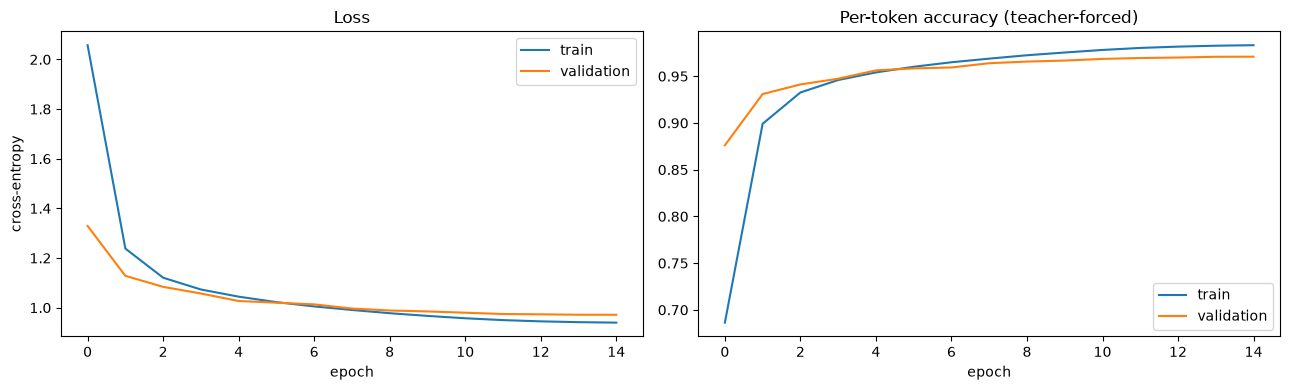

In [ ]:
if history is None:
    print("Training was skipped this session, so there are no curves to plot.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"],   label="validation")
    axes[0].set_title("Loss"); axes[0].set_ylabel("cross-entropy")
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"],   label="validation")
    axes[1].set_title("Per-token accuracy (teacher-forced)")
    for ax in axes: ax.set_xlabel("epoch"); ax.legend()
    plt.tight_layout(); plt.show()

Note: the accuracy printed during training is measured under teacher forcing, meaning the model is handed the correct prefix at every position. At inference it has to build on its own earlier predictions, where one mistake corrupts everything after it. Training-time token accuracy is systematically optimistic, and the real measure is the one from the held-out test set in Section 8.

## 7. Inferencing
With the model trained, we can now hand it an image it has never seen, and have it produce LaTeX.

`model.eval()` switches the model into evaluation mode, which matters because some layers behave differently depending on mode, with BatchNorm using running statistics instead of batch statistics and dropout switching off. Forgetting this call is a classic source of mysteriously worse predictions. `@torch.no_grad()` disables gradient tracking since nothing is being learned, which saves a lot of memory and time.

The model can't emit a whole expression at once. It produces one token, then reconsiders with that token now part of its input, then produces the next. `predict()` does this by preprocessing the image and running the encoder exactly once, since the image doesn't change and the 720 visual tokens can be reused at every step. The sequence starts as just `<sos>`. From there it runs the decoder over the sequence so far, takes the logits at the final position, picks the highest-scoring token, appends it, and repeats until `<eos>` appears or `max_len` is hit. `decode()` turns the accumulated IDs back into a LaTeX string.

The important difference from training is that there's no answer to feed in, so from the second step onward the model is consuming its own previous outputs. This is why early mistakes compound, since a wrong token becomes part of the context for every token after it. It's also the gap teacher forcing leaves behind: the model trained on perfect history and now has to operate on imperfect history.

Taking the single highest-scoring token at each step is greedy decoding. It's fast and simple, but it commits irreversibly, and a token that looks best in isolation can lead into a sequence that's collectively much worse with no way to back out. Beam search is the alternative, keeping several candidate sequences alive at once and scoring them as wholes, which usually produces better output from the exact same weights. This notebook uses greedy, but beam search lives in the application backend.

The last line is a spot check, showing four random test images with prediction above ground truth so failures can be looked at rather than only counted.

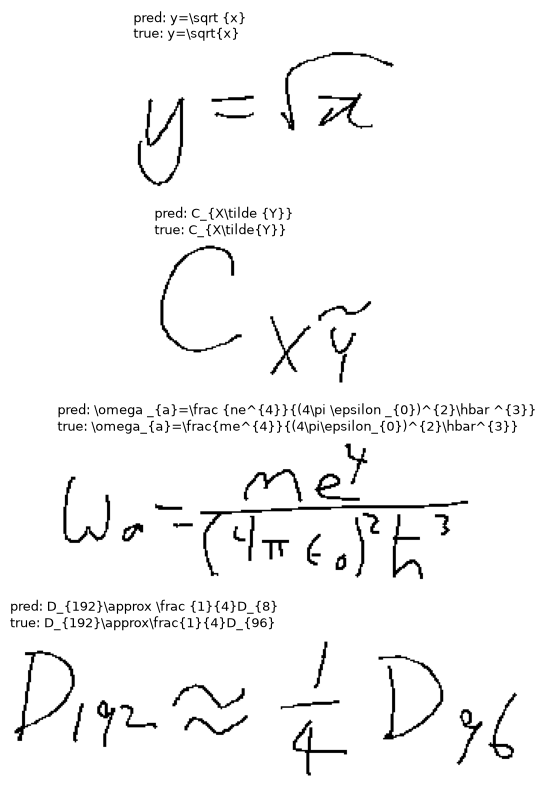

In [ ]:
model.load_state_dict(torch.load("checkpoints/best.pt", map_location=device))
model.eval()

@torch.no_grad()
def predict(image: Image.Image, max_len=MAX_LEN) -> str:
    x = preprocess(image).unsqueeze(0).to(device)
    memory = model.encoder(x)
    seq = torch.tensor([[SOS_ID]], device=device)
    for _ in range(max_len):
        t = model.pos1d(model.embed(seq))
        L = seq.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=device), diagonal=1)
        h = model.decoder(t, memory, tgt_mask=causal)
        next_id = model.head(h[:, -1]).argmax(-1, keepdim=True)
        seq = torch.cat([seq, next_id], dim=1)
        if next_id.item() == EOS_ID:
            break
    return decode(seq[0].tolist())

fig, axes = plt.subplots(4, 1, figsize=(12, 8))
for ax, (_, row) in zip(axes, test_df.sample(4, random_state=SEED).iterrows()):
    img = Image.open(row["image"])
    pred = predict(img)
    ax.imshow(img.convert("L"), cmap="gray"); ax.axis("off")
    ax.set_title(f"pred: {pred}\ntrue: {row['latex']}", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 8. Evaluating the Model on the Test Set

A model that works on examples you've been staring at proves very little. This section produces the real numbers on the held-out test images.

Comparing raw strings would be unfair, because LaTeX offers many ways to typeset the same expression. `x^{2}` and `x^2` render identically; `\dfrac` and `\frac` differ only in display size; and `\left(` and `(` produce the same parenthesis. A model can be completely correct and still mismatch the reference on pure notation convention, and that problem gets worse when comparing two models trained on different data.

`canon()` neutralizes this before anything gets compared. It drops cosmetic tokens like `\left`, `\right`, spacing commands and `\displaystyle`, maps known equivalents onto one spelling, and collapses single-element braces so `x^{2}` becomes `x^2`. What's left is a canonical token list, so the comparison measures recognition rather than formatting taste.

Two metrics then get computed. Exact match is the fraction of test images where the canonicalized prediction is identical to the canonicalized truth. It's the strictest measure possible, since one wrong symbol anywhere scores zero for that expression, and it's also the most realistic one, because a transcription with one wrong exponent isn't usable output.

Exact match being all-or-nothing hides the difference between a near-perfect prediction and complete garbage, which is what the second metric is for. Edit distance, also called Levenshtein distance, counts the minimum number of single-unit edits needed to turn the prediction into the truth, where an edit is a substitution, insertion, or deletion. `edit_distance()` computes it with dynamic programming, building a table of best-known distances between prefixes. Dividing by the length of the reference gives a per-unit error rate:

    error rate = (substitutions + deletions + insertions) / length of truth

Zero is perfect, 0.1 means roughly one unit in ten is wrong, and it can exceed 1.0 since a prediction much longer than the truth racks up more insertions than the truth has units.

Both get reported because they answer different questions. Exact match asks how often the output is fully right. Error rate asks, when it's wrong, how wrong.


In [ ]:
STRIP_TOKENS = {"\\left", "\\right", "\\,", "\\;", "\\!", "\\:", "\\ ",
                "\\textstyle", "\\displaystyle", "\\limits", " "}
ALIASES = {"\\dfrac": "\\frac", "\\tfrac": "\\frac", "\\cdots": "\\ldots",
           "\\to": "\\rightarrow"}

# focuses on strings and ignore formatting styles
def canon(latex: str):
    '''Canonical token list for fair comparison across LaTeX conventions.'''
    toks = [ALIASES.get(t, t) for t in tokenize(str(latex)) if t not in STRIP_TOKENS]
    out, i = [], 0
    while i < len(toks):                      # x^{2} -> x^2 (collapse singleton braces)
        if (toks[i] in ("^", "_") and i + 3 < len(toks)
                and toks[i+1] == "{" and toks[i+3] == "}"):
            out += [toks[i], toks[i+2]]; i += 4
        else:
            out.append(toks[i]); i += 1
    return out

# Levenshtein distance 
def edit_distance(a, b):
    dp = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, dp[0] = dp[0], i
        for j in range(1, len(b) + 1):
            prev, dp[j] = dp[j], min(dp[j] + 1, dp[j-1] + 1, prev + (a[i-1] != b[j-1]))
    return dp[-1]

def score(pred, true):
    p, t = canon(pred), canon(true)
    return {"exact": p == t, "cer": edit_distance(p, t) / max(1, len(t))}

ours = []
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="our model on test"):
    pred = predict(Image.open(row["image"]))
    ours.append({"id": row["id"], "true": row["latex"], "pred": pred, **score(pred, row["latex"])})
ours = pd.DataFrame(ours)
print(f"OUR MODEL   — exact match: {ours['exact'].mean():.1%}   mean CER: {ours['cer'].mean():.3f}")

our model on test: 100%|██████████| 500/500 [00:59<00:00,  8.45it/s]

OUR MODEL   — exact match: 63.8%   mean CER: 0.078


## 9. Model Comparison: pix2tex

A number on its own isn't interpretable. Is our exact-match score good? The only way to find out is to compare against something, and that something here is pix2tex, an established open-source image-to-LaTeX model.

This is a baseline: an existing system, built independently, solving the same task. Beating one is evidence the model learned something real. Losing to one tells you where the ceiling sits and what needs fixing.

Three things make the comparison valid:

- The images are identical, since pix2tex runs over the same `test_df`, not a different or easier set.
- The metrics and the code are identical, since both models' outputs go through the same `score()` function, so exact match and error rate mean precisely the same thing for each.
- Both get the same canonicalization, which is the one that matters most: pix2tex trained on a different corpus and prefers different notation, so without `canon` normalizing both sides it would be penalized for writing `\dfrac` where MathWriting writes `\frac`, turning a measurement artifact into an apparent advantage.

Note: This model is trained and tested on MathWriting, so it matches the test data's handwriting style and notation conventions. pix2tex is trained elsewhere, largely on typeset and rendered formulas, and is being evaluated out of domain. A favorable result here means better on this distribution, not better in general.

In [ ]:
# NOTE: install pix2tex from a terminal BEFORE starting this kernel:
#   .\venv\Scripts\python.exe -m pip install pix2tex
from pix2tex.cli import LatexOCR

baseline = LatexOCR()      
p2t = []
for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc="pix2tex on test"):
    img = Image.open(row["image"]).convert("RGB")
    try:
        pred = baseline(img)
    except Exception:
        pred = ""
    p2t.append({"id": row["id"], "true": row["latex"], "pred": pred, **score(pred, row["latex"])})
p2t = pd.DataFrame(p2t)
print(f"PIX2TEX     — exact match: {p2t['exact'].mean():.1%}   mean CER: {p2t['cer'].mean():.3f}")

c:\Users\muhdn\OneDrive\Desktop\projects\ocr\venv\Lib\site-packages\albumentations\__init__.py:24: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.24). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()
c:\Users\muhdn\OneDrive\Desktop\projects\ocr\venv\Lib\site-packages\pydantic\_internal\_serializers.py:44: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `dict[str, any]` - serialized value may not be as expected [field_name='noise_params', input_value=UniformParams(noise_type=... 0.058823529411764705)]), input_type=UniformParams])
  v = handler(item, index)
c:\Users\muhdn\OneDrive\Desktop\projects\ocr\venv\Lib\site-packages\pydantic\main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `dict[str, any]` - serialized value may not be as expected [field_n

PIX2TEX     — exact match: 0.0%   mean CER: 4.614


The summary table gives the headline numbers side by side, and the qualitative comparison shows five random test images with both models' outputs underneath. That second one is where the useful information is, because aggregate metrics tell you how much is wrong while individual failures tell you what kind of thing is wrong, and only the second kind of knowledge suggests what to do next.

                        model  exact_match  mean_CER
ours (trained on MathWriting)        0.638  0.077922
      pix2tex (off-the-shelf)        0.000  4.613797


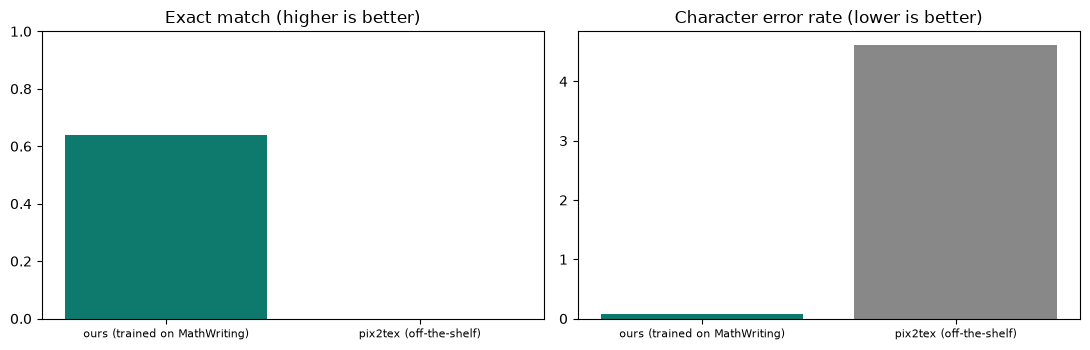

In [18]:
summary = pd.DataFrame({
    "model": ["ours (trained on MathWriting)", "pix2tex (off-the-shelf)"],
    "exact_match": [ours["exact"].mean(), p2t["exact"].mean()],
    "mean_CER":    [ours["cer"].mean(),   p2t["cer"].mean()],
})
print(summary.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(summary["model"], summary["exact_match"], color=["#0e7a6d", "#888"])
axes[0].set_title("Exact match (higher is better)"); axes[0].set_ylim(0, 1)
axes[1].bar(summary["model"], summary["mean_CER"], color=["#0e7a6d", "#888"])
axes[1].set_title("Character error rate (lower is better)")
for ax in axes: ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()


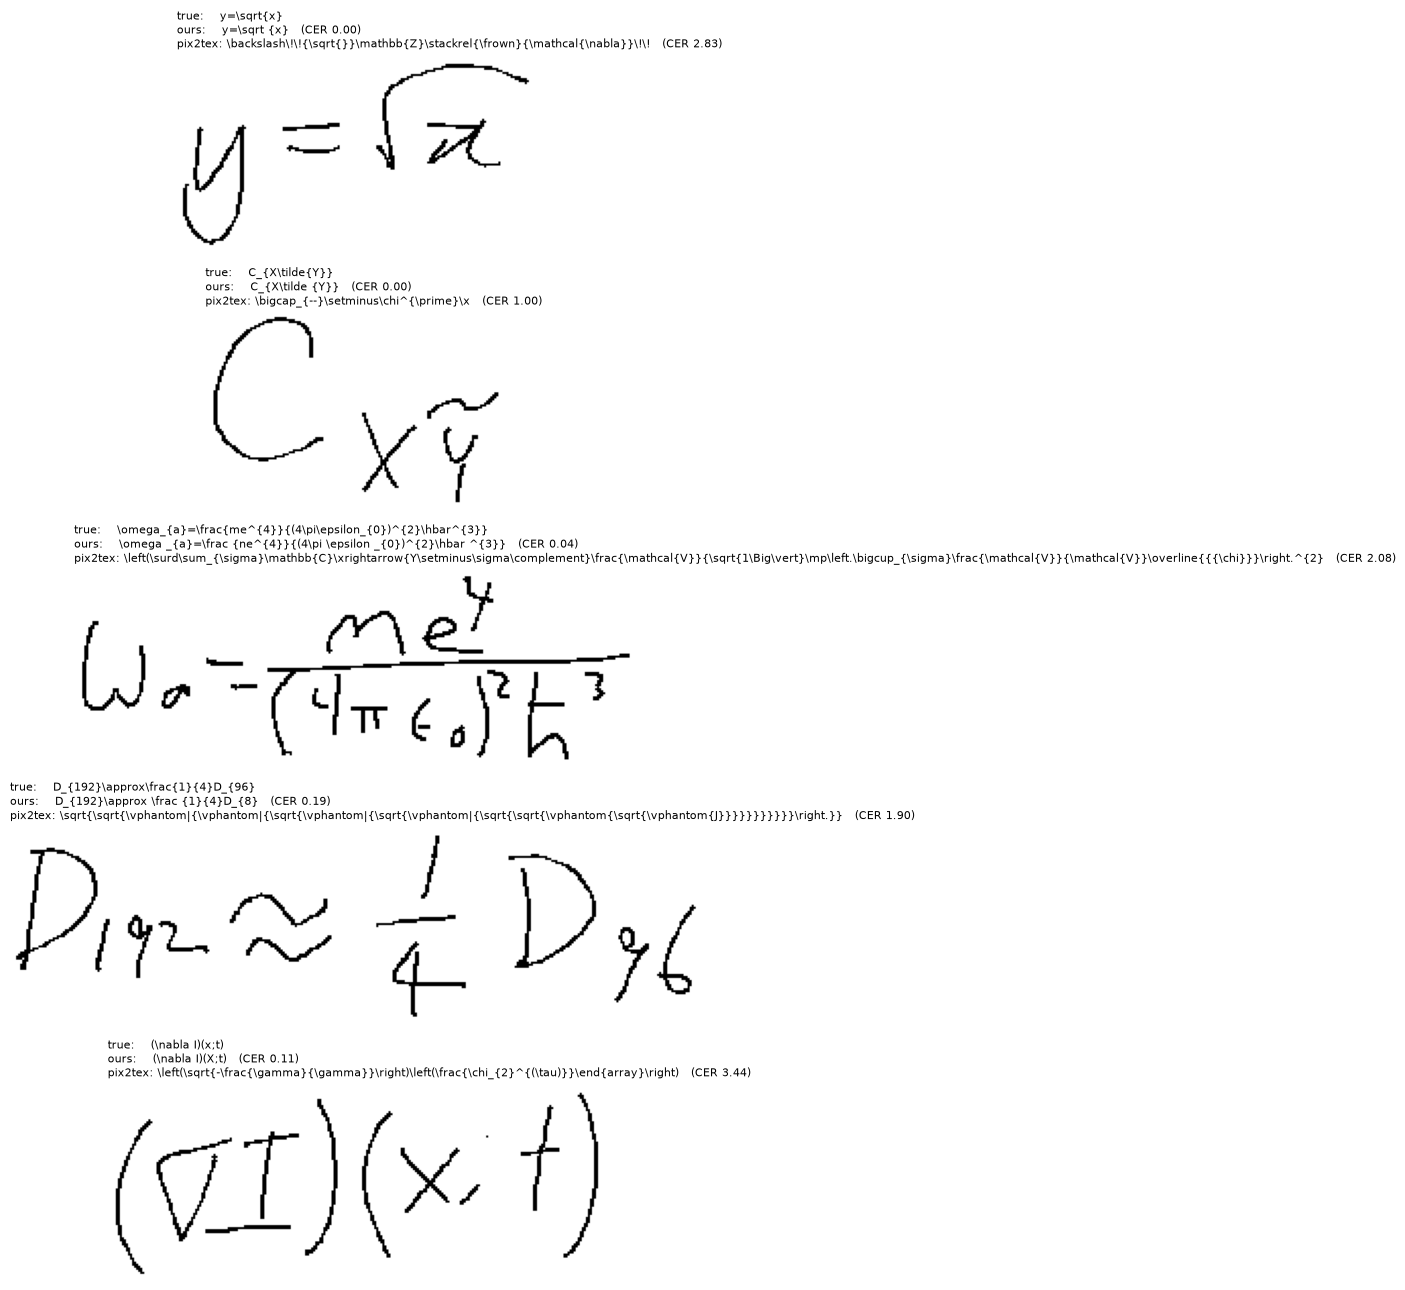

In [ ]:
# side-by-side LaTeX label generated from each model
merged = ours.merge(p2t, on=["id", "true"], suffixes=("_ours", "_p2t"))
sample = merged.sample(5, random_state=SEED)
fig, axes = plt.subplots(len(sample), 1, figsize=(12, 2.6 * len(sample)))
for ax, (_, r) in zip(np.atleast_1d(axes), sample.iterrows()):
    img_path = test_df[test_df["id"] == r["id"]].iloc[0]["image"]
    ax.imshow(Image.open(img_path).convert("L"), cmap="gray"); ax.axis("off")
    ax.set_title(f"true:    {r['true']}\nours:    {r['pred_ours']}   (CER {r['cer_ours']:.2f})\n"
                 f"pix2tex: {r['pred_p2t']}   (CER {r['cer_p2t']:.2f})",
                 fontsize=8, loc="left")
plt.tight_layout(); plt.show()


## 10. Exporting the Model

Training left the weights sitting in GPU memory inside a notebook. This section packages them so a separate web application process can load and serve the model.

PyTorch keeps a model's architecture, meaning the `Math2LaTeX` class, separate from its learned parameters, meaning the millions of numbers filled in during training. `state_dict` is just those numbers as a dictionary of tensors. Saving it rather than the whole model object is the recommended approach, since it's portable across code changes and doesn't depend on reconstructing the original Python environment exactly. The consequence is that loading needs both halves: construct the class first, then pour the weights in.

Weights alone would be unusable, because they encode nothing about how to communicate with them. Three things travel together in the bundle.

- `itos`: the vocabulary list. The output layer emits one score per vocabulary entry, identified only by position, so without the same `itos` in the same order those positions map to the wrong tokens and the output is noise. The vocabulary is as much part of the trained model as the weights are
- `config`, holding `d_model`, `img_h`, `img_w` and `max_len`: rebuilds the architecture at matching dimensions and to preprocess incoming images exactly the way training images were preprocessed. Feed the model a differently-sized or differently-normalized image and predictions degrade in a way that looks like a bad model rather than a config mismatch
- `state_dict`: the weights

In [ ]:
bundle = {
    "state_dict": model.state_dict(),
    "itos": itos,
    "config": {"d_model": D_MODEL, "img_h": IMG_H, "img_w": IMG_W, "max_len": MAX_LEN},
}
torch.save(bundle, "math2latex_model.pt")
print(f"Saved math2latex_model.pt ({os.path.getsize('math2latex_model.pt')/1e6:.1f} MB)")

Saved math2latex_model.pt (21.7 MB)


The commented-out code documents the other half of the contract: build `Math2LaTeX` sized from the saved vocabulary, load the weights, and call `.eval()`. `map_location="cpu"` lets a GPU-trained model load on a machine without one.

In [ ]:
# App backend reload:
# b = torch.load("math2latex_model.pt", map_location="cpu")
# model = Math2LaTeX(len(b["itos"])); model.load_state_dict(b["state_dict"]); model.eval()